# Modelling car insurance claim outcomes

<center><img src="car.jpg" alt="Parked car" width="400" height="300"></center>

An insurer wants a model that predicts whether a customer will make a claim during the policy period. They have little infrastructure for running machine learning in production, so the brief is deliberately narrow: **find the single feature that gives the best logistic regression model**, measured by accuracy.

The data (`car_insurance.csv`) has 10,000 customers.

| Column | Description |
|--------|-------------|
| `id` | Unique client identifier |
| `age` | Age band: 0 = 16-25, 1 = 26-39, 2 = 40-64, 3 = 65+ |
| `gender` | 0 = female, 1 = male |
| `driving_experience` | Years driving: 0-9, 10-19, 20-29, 30+ |
| `education` | None, high school or university |
| `income` | Poverty, working class, middle class or upper class |
| `credit_score` | Credit score between 0 and 1 |
| `vehicle_ownership` | 1 = owns the vehicle, 0 = paying off finance |
| `vehicle_year` | Registered before or after 2015 |
| `married` | 1 = married |
| `children` | 1 = has children |
| `postal_code` | Postal code |
| `annual_mileage` | Miles driven per year |
| `vehicle_type` | Sedan or sports car |
| `speeding_violations` | Number of speeding violations |
| `duis` | Number of drink-driving offences |
| `past_accidents` | Number of previous accidents |
| `outcome` | 1 = made a claim (target) |

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from statsmodels.formula.api import logit

cars = pd.read_csv("car_insurance.csv")
cars.head()

,id,age,gender,driving_experience,education,income,credit_score,vehicle_ownership,vehicle_year,married,children,postal_code,annual_mileage,vehicle_type,speeding_violations,duis,past_accidents,outcome
0,569520,3,0,0-9y,high school,upper class,0.629027,1.0,after 2015,0.0,1.0,10238,12000.0,sedan,0,0,0,0.0
1,750365,0,1,0-9y,none,poverty,0.357757,0.0,before 2015,0.0,0.0,10238,16000.0,sedan,0,0,0,1.0
2,199901,0,0,0-9y,high school,working class,0.493146,1.0,before 2015,0.0,0.0,10238,11000.0,sedan,0,0,0,0.0
3,478866,0,1,0-9y,university,working class,0.206013,1.0,before 2015,0.0,1.0,32765,11000.0,sedan,0,0,0,0.0
4,731664,1,1,10-19y,none,working class,0.388366,1.0,before 2015,0.0,0.0,32765,12000.0,sedan,2,0,1,1.0


## 1. Data checks

In [2]:
cars.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   10000 non-null  int64  
 1   age                  10000 non-null  int64  
 2   gender               10000 non-null  int64  
 3   driving_experience   10000 non-null  str    
 4   education            10000 non-null  str    
 5   income               10000 non-null  str    
 6   credit_score         9018 non-null   float64
 7   vehicle_ownership    10000 non-null  float64
 8   vehicle_year         10000 non-null  str    
 9   married              10000 non-null  float64
 10  children             10000 non-null  float64
 11  postal_code          10000 non-null  int64  
 12  annual_mileage       9043 non-null   float64
 13  vehicle_type         10000 non-null  str    
 14  speeding_violations  10000 non-null  int64  
 15  duis                 10000 non-null  int64  
 16

About 31% of customers made a claim, so a model that always predicts "no claim" is right 69% of the time. That is the baseline.

In [3]:
claim_rate = cars["outcome"].mean()
print(f"Claim rate: {claim_rate:.3f}")
print(f"Majority-class baseline accuracy: {1 - claim_rate:.3f}")

Claim rate: 0.313
Majority-class baseline accuracy: 0.687


## 2. Train/test split and missing values

The data is split first so that accuracy is measured on customers the models have not seen. `credit_score` and `annual_mileage` each have just under 10% missing values; they are filled with the **training** mean.

In [4]:
train, test = train_test_split(cars, test_size=0.25, random_state=42, stratify=cars["outcome"])
train, test = train.copy(), test.copy()

for col in ["credit_score", "annual_mileage"]:
    fill_value = train[col].mean()
    train[col] = train[col].fillna(fill_value)
    test[col] = test[col].fillna(fill_value)

print(train.shape, test.shape)
print("Missing values left:", train.isna().sum().sum() + test.isna().sum().sum())

(7500, 18) (2500, 18)
Missing values left: 0


## 3. One logistic regression per feature

Each feature gets its own model. Text columns, the `age` bands and `postal_code` are treated as categorical. Accuracy uses a 0.5 probability threshold.

In [5]:
features = cars.drop(columns=["id", "outcome"]).columns
categorical = ["age", "driving_experience", "education", "income", "vehicle_year", "vehicle_type", "postal_code"]

rows = []
for col in features:
    term = f"C({col})" if col in categorical else col
    model = logit(f"outcome ~ {term}", data=train).fit(disp=False)
    train_acc = ((model.predict(train) >= 0.5) == train["outcome"]).mean()
    test_acc = ((model.predict(test) >= 0.5) == test["outcome"]).mean()
    rows.append({"feature": col, "train_accuracy": train_acc, "test_accuracy": test_acc})

results = pd.DataFrame(rows).sort_values("test_accuracy", ascending=False).reset_index(drop=True)
results.round(4)

,feature,train_accuracy,test_accuracy
0,age,0.7760,0.7708
1,driving_experience,0.7808,0.7660
2,income,0.7428,0.7416
3,vehicle_ownership,0.7381,0.7260
4,credit_score,0.7069,0.7020
5,postal_code,0.6979,0.7012
6,annual_mileage,0.6903,0.6908
7,gender,0.6867,0.6868
8,education,0.6867,0.6868
9,vehicle_year,0.6867,0.6868


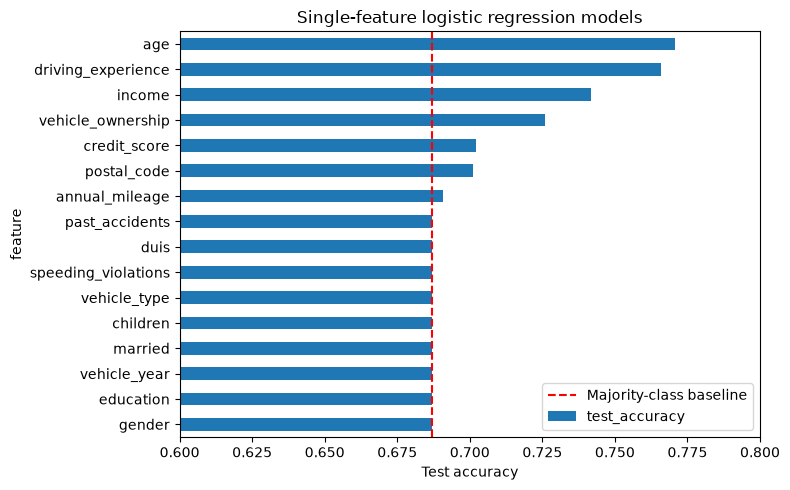

In [6]:
ax = results.set_index("feature")["test_accuracy"].sort_values().plot.barh(figsize=(8, 5))
ax.axvline(1 - test["outcome"].mean(), color="red", linestyle="--", label="Majority-class baseline")
ax.set_xlabel("Test accuracy")
ax.set_title("Single-feature logistic regression models")
ax.set_xlim(0.6, 0.8)
ax.legend()
plt.tight_layout()
plt.show()

## 4. The best feature

In [7]:
best_feature_df = results.loc[[0], ["feature", "test_accuracy"]].rename(
    columns={"feature": "best_feature", "test_accuracy": "best_accuracy"})
best_feature_df

,best_feature,best_accuracy
0,age,0.7708


Claim rates by driving experience and by age band:

In [8]:
display(cars.groupby("driving_experience")["outcome"].agg(["mean", "count"]).round(3))
display(cars.groupby("age")["outcome"].agg(["mean", "count"]).round(3))
pd.crosstab(cars["age"], cars["driving_experience"])

,mean,count
driving_experience,,
0-9y,0.628,3530
10-19y,0.239,3299
20-29y,0.051,2119
30y+,0.019,1052


,mean,count
age,,
0,0.718,2016
1,0.337,3063
2,0.156,2931
3,0.098,1990


driving_experience,0-9y,10-19y,20-29y,30y+
age,,,,
0,2016,0,0,0
1,683,2380,0,0
2,533,587,1811,0
3,298,332,308,1052


## Conclusion

- `age` is the best single predictor on held-out customers (77.1% accuracy against a 68.7% baseline), with `driving_experience` half a point behind (76.6%). On the training data the order is reversed, so the two are effectively tied.
- They are close to being the same variable: every customer in the youngest band has under ten years of experience, and only the oldest band has anyone with 30 or more. Both capture the same pattern, which is that claim rates fall steeply with experience, from 63% of drivers with under ten years to 2% of those with 30 or more.
- Driving experience is arguably the better one to use in practice, since it describes the risk directly and has the higher training accuracy.
- Five features (`gender`, `education`, `vehicle_year`, `married`, `children`) score exactly the baseline. A single weak predictor never pushes the predicted probability past 0.5, so those models predict "no claim" for everyone.

Next steps would be a multi-feature model and a metric such as ROC AUC that does not depend on one threshold.